## Preparation

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.preprocessing import LabelEncoder

## Load Dataset

In [2]:
df = pd.read_csv('drug200.csv')

## EDA

In [3]:
print("Informasi dataset")
df.info()

Informasi dataset
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Age          200 non-null    int64  
 1   Sex          200 non-null    str    
 2   BP           200 non-null    str    
 3   Cholesterol  200 non-null    str    
 4   Na_to_K      200 non-null    float64
 5   Drug         200 non-null    str    
dtypes: float64(1), int64(1), str(4)
memory usage: 9.5 KB


In [4]:
print("Deskripsi statistik")
df.describe()

Deskripsi statistik


,Age,Na_to_K
count,200.000000,200.000000
mean,44.315000,16.084485
std,16.544315,7.223956
min,15.000000,6.269000
25%,31.000000,10.445500
50%,45.000000,13.936500
75%,58.000000,19.380000
max,74.000000,38.247000


In [5]:
print("10 data teratas")
df.head(10)

10 data teratas


,Age,Sex,BP,Cholesterol,Na_to_K,Drug
0,23,F,HIGH,HIGH,25.355,drugY
1,47,M,LOW,HIGH,13.093,drugC
2,47,M,LOW,HIGH,10.114,drugC
3,28,F,NORMAL,HIGH,7.798,drugX
4,61,F,LOW,HIGH,18.043,drugY
5,22,F,NORMAL,HIGH,8.607,drugX
6,49,F,NORMAL,HIGH,16.275,drugY
7,41,M,LOW,HIGH,11.037,drugC
8,60,M,NORMAL,HIGH,15.171,drugY
9,43,M,LOW,NORMAL,19.368,drugY


In [7]:
print(f"Isi data (baris, kolom) : {df.shape} ")

Isi data (baris, kolom) : (200, 6) 


In [8]:
df.isnull().sum()

Age            0
Sex            0
BP             0
Cholesterol    0
Na_to_K        0
Drug           0
dtype: int64

In [10]:
df.duplicated().sum()

np.int64(0)

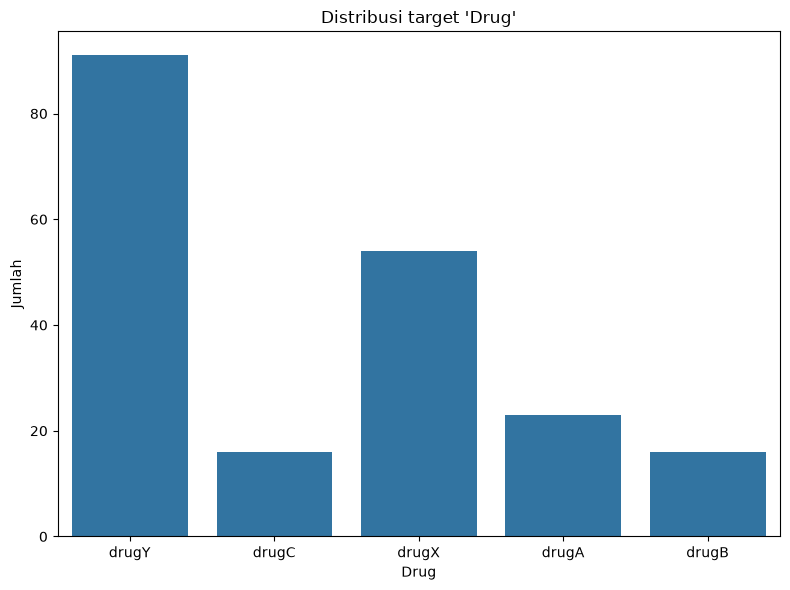

In [11]:
plt.figure(figsize=(8,6))
sns.countplot(data=df, x='Drug')
plt.title("Distribusi target 'Drug'")
plt.ylabel("Jumlah")
plt.tight_layout()
plt.show()

## Preprocessing

In [26]:
gender = LabelEncoder()
gender.fit(df['Sex'])
df['Sex_Code'] = gender.transform(df['Sex'])
df[['Sex', 'Sex_Code']].head(10)

,Sex,Sex_Code
0,F,0
1,M,1
2,M,1
3,F,0
4,F,0
5,F,0
6,F,0
7,M,1
8,M,1
9,M,1


In [25]:
kolestrol = LabelEncoder()
kolestrol.fit(df['Cholesterol'])
df['Cholesterol_Code'] = kolestrol.transform(df['Cholesterol'])
df[['Cholesterol', 'Cholesterol_Code']].head(10)

,Cholesterol,Cholesterol_Code
0,HIGH,0
1,HIGH,0
2,HIGH,0
3,HIGH,0
4,HIGH,0
5,HIGH,0
6,HIGH,0
7,HIGH,0
8,HIGH,0
9,NORMAL,1


In [28]:
bp = LabelEncoder()
bp.fit(df['BP'])
df['BP_Code'] = bp.transform(df['BP'])
df[['BP', 'BP_Code']].head(10)

,BP,BP_Code
0,HIGH,0
1,LOW,1
2,LOW,1
3,NORMAL,2
4,LOW,1
5,NORMAL,2
6,NORMAL,2
7,LOW,1
8,NORMAL,2
9,LOW,1


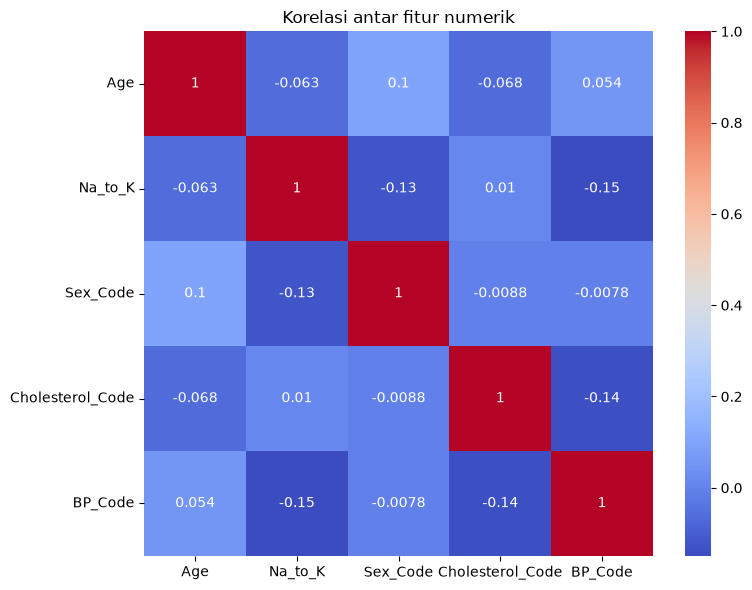

In [30]:
plt.figure(figsize=(8,6))
sns.heatmap(df.corr(numeric_only=True), cmap='coolwarm', cbar=True, annot=True)
plt.title("Korelasi antar fitur numerik")
plt.tight_layout()
plt.show()

## Feature Engineering

In [33]:
X = df.drop(columns=['Sex', 'BP', 'Cholesterol', 'Drug'])
y = df['Drug']

## Split Data

In [34]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=67
)

print(f"Jumlah data latih : {len(X_train)}")
print(f"Jumlah data uji: {len(y_test)}")

Jumlah data latih : 160
Jumlah data uji: 40


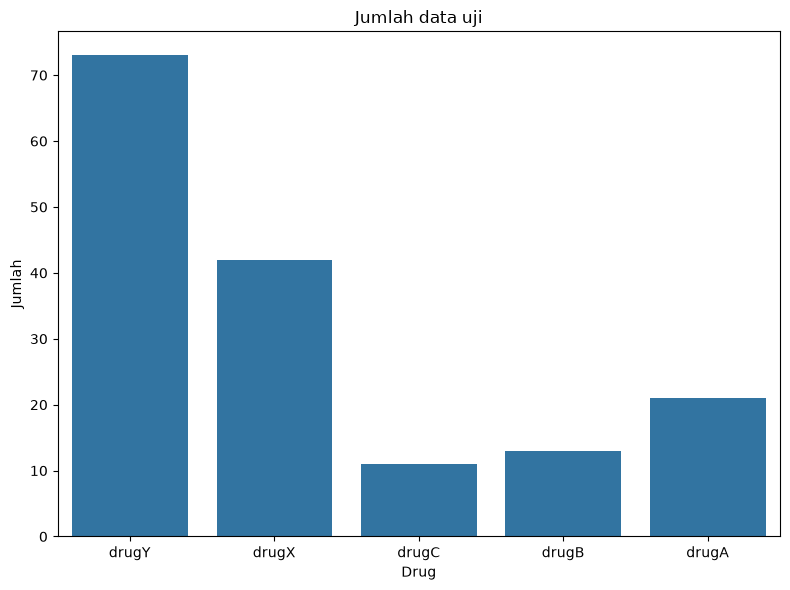

In [36]:
plt.figure(figsize=(8,6))
sns.countplot(data=df, x=y_train)
plt.title("Jumlah data uji")
plt.ylabel("Jumlah")
plt.tight_layout()
plt.show()

## Modeling

In [ ]:
# membuat model
model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    random_state=67
)

# melatih model
model.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",67
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap

In [ ]:
# membuat prediksi
y_pred = model.predict(X_test)
y_pred

array(['drugX', 'drugY', 'drugY', 'drugY', 'drugA', 'drugY', 'drugY',
       'drugY', 'drugX', 'drugY', 'drugY', 'drugY', 'drugC', 'drugC',
       'drugX', 'drugY', 'drugB', 'drugX', 'drugB', 'drugY', 'drugY',
       'drugX', 'drugY', 'drugA', 'drugC', 'drugX', 'drugX', 'drugX',
       'drugX', 'drugX', 'drugC', 'drugB', 'drugY', 'drugY', 'drugY',
       'drugX', 'drugC', 'drugX', 'drugY', 'drugY'], dtype=object)

## Evaluation

In [43]:
print("=" * 15)
print("Evaluasi Model")
print("=" * 15)
print(f"Akurasi : {accuracy_score(y_test, y_pred) * 100:.2f}%\n")
print("Classification Report")
print(classification_report(y_test, y_pred))

Evaluasi Model
Akurasi : 100.00%

Classification Report
              precision    recall  f1-score   support

       drugA       1.00      1.00      1.00         2
       drugB       1.00      1.00      1.00         3
       drugC       1.00      1.00      1.00         5
       drugX       1.00      1.00      1.00        12
       drugY       1.00      1.00      1.00        18

    accuracy                           1.00        40
   macro avg       1.00      1.00      1.00        40
weighted avg       1.00      1.00      1.00        40



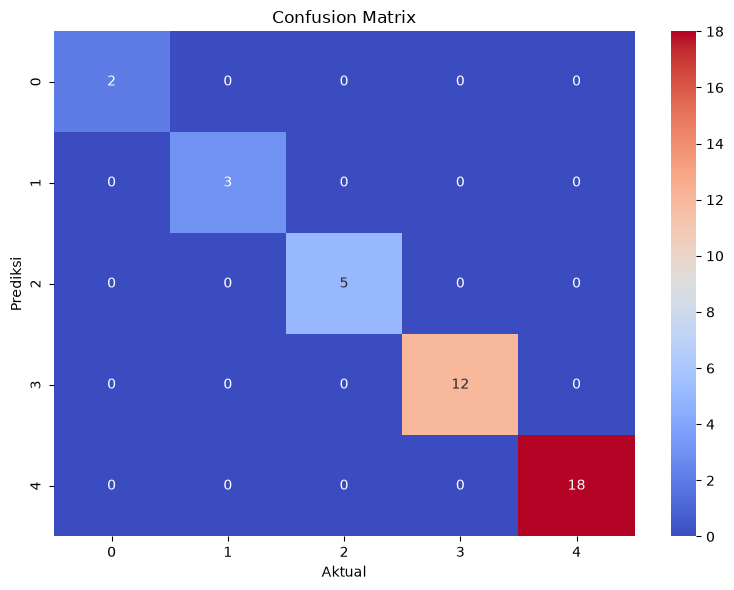

In [45]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8,6))
sns.heatmap(cm, cmap='coolwarm', cbar=True, annot=True, fmt='d')
plt.title("Confusion Matrix")
plt.xlabel("Aktual")
plt.ylabel("Prediksi")
plt.tight_layout()
plt.show()